# Desafio de otimização de hiperparâmetros · Aula 7.5

Queremos descobrir qual estratégia encontra uma boa configuração para classificar vinhos a partir de medidas químicas. Vamos usar o mesmo **Gradient Boosting** com **Grid Search, Random Search e Optuna**. A acurácia na validação escolhe a configuração de cada estratégia. O teste mostra como essas escolhas se saem com outros vinhos.

## 1. Conhecer os dados

A base Wine contém **178 vinhos**, cada um com **13 medidas químicas** e um rótulo entre **três classes**. Conferimos a distribuição das classes, a faixa das medidas e a presença de valores ausentes. O gráfico mostra duas medidas para visualizar os dados. O modelo recebe as 13.

178 vinhos e 13 características
Valores ausentes 0


,Amostras
Classe,
0,59
1,71
2,48


,min,mean,max
alcohol,11.03,13.00,14.83
malic_acid,0.74,2.34,5.80
ash,1.36,2.37,3.23
alcalinity_of_ash,10.60,19.49,30.00
magnesium,70.00,99.74,162.00
total_phenols,0.98,2.30,3.88
flavanoids,0.34,2.03,5.08
nonflavanoid_phenols,0.13,0.36,0.66
proanthocyanins,0.41,1.59,3.58
color_intensity,1.28,5.06,13.00


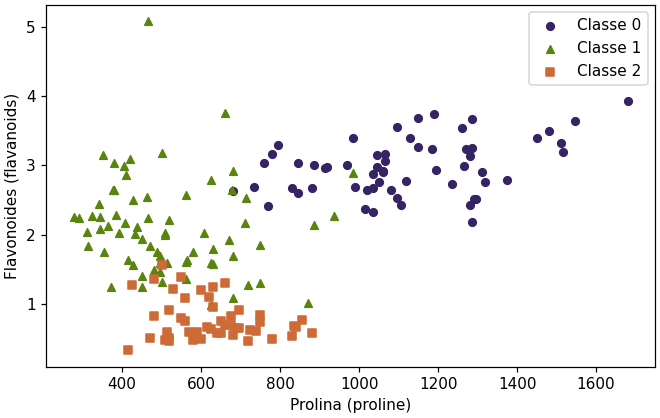

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from IPython.display import display
from optuna.trial import TrialState
from scipy.stats import loguniform, randint
from sklearn.datasets import load_wine
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split,
)

vinhos = load_wine(as_frame=True)
X, y = vinhos.data, vinhos.target

print(f"{X.shape[0]} vinhos e {X.shape[1]} características")
print(f"Valores ausentes {X.isna().sum().sum()}")
display(y.value_counts().sort_index().rename_axis("Classe").to_frame("Amostras"))
display(X.agg(["min", "mean", "max"]).T.round(2))

fig, ax = plt.subplots(figsize=(6, 3.8), layout="constrained")
for classe, cor, marcador in [(0, "#352364", "o"), (1, "#59840D", "^"), (2, "#CE6A36", "s")]:
    grupo = X[y == classe]
    ax.scatter(grupo["proline"], grupo["flavanoids"], c=cor, marker=marcador,
               s=25, label=f"Classe {classe}")
ax.set(xlabel="Prolina (proline)", ylabel="Flavonoides (flavanoids)")
ax.legend()
plt.show()

## 2. Separar os vinhos que servirão para o teste

Guardamos 25% da base para avaliar os modelos no fim. Nos 75% restantes, criamos três folds estratificados, que mantêm aproximadamente a proporção de cada classe. Cada estratégia usa **os mesmos folds** e compara a **acurácia média** das configurações.

In [2]:
SEMENTE = 42
N_TENTATIVAS = 12
CHECKPOINTS = [25, 50, 75, 100, 150]
N_RODADAS = CHECKPOINTS[-1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEMENTE, stratify=y,
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE)
folds = list(cv.split(X_train, y_train))

print(f"Treino {len(X_train)} | teste {len(X_test)}")
print("Amostras de validação por fold", [len(idx_val) for _, idx_val in folds])

Treino 133 | teste 45
Amostras de validação por fold [45, 44, 44]


## 3. Definir o espaço de busca e testar Grid e Random

As três buscas têm **12 tentativas** e até **150 rodadas por fold**. Variamos a profundidade máxima da árvore, a taxa de aprendizado e o mínimo de amostras em uma folha.

| Hiperparâmetro | Grid Search | Random Search e Optuna |
|---|---|---|
| `max_depth` | 1, 2 e 3 | Inteiros de 1 a 3 |
| `learning_rate` | 0,03 e 0,10 | Entre 0,02 e 0,15, em escala logarítmica |
| `min_samples_leaf` | 1 e 5 | Inteiros de 1 a 5 |

O Grid testa as 12 combinações da tabela. O Random sorteia 12 configurações dentro dos intervalos. Guardamos as configurações escolhidas para treiná-las em todo o conjunto de treino depois.

In [3]:
modelo_base = GradientBoostingClassifier(n_estimators=N_RODADAS, random_state=SEMENTE)

grid = GridSearchCV(
    modelo_base,
    param_grid={
        "max_depth": [1, 2, 3],
        "learning_rate": [0.03, 0.10],
        "min_samples_leaf": [1, 5],
    },
    scoring="accuracy", cv=folds, refit=False, n_jobs=1, error_score="raise",
)
random_search = RandomizedSearchCV(
    modelo_base,
    param_distributions={
        "max_depth": randint(1, 4),
        "learning_rate": loguniform(0.02, 0.15),
        "min_samples_leaf": randint(1, 6),
    },
    n_iter=N_TENTATIVAS, scoring="accuracy", cv=folds,
    random_state=SEMENTE, refit=False, n_jobs=1, error_score="raise",
)

buscas = {"Grid Search": grid, "Random Search": random_search}
tempos = {}
for nome, busca in buscas.items():
    inicio = perf_counter()
    busca.fit(X_train, y_train)
    tempos[nome] = perf_counter() - inicio

## 4. Usar os resultados anteriores com Optuna

O TPE usa as tentativas anteriores para orientar as próximas sugestões. Cada tentativa treina um modelo por fold e avalia a acurácia em etapas. O `warm_start` mantém as árvores já treinadas quando acrescentamos outras. Depois que os três folds chegam à mesma etapa, o `MedianPruner` pode interromper a tentativa se o desempenho parcial estiver abaixo da referência das anteriores.

In [4]:
def objective(trial):
    parametros = {
        "max_depth": trial.suggest_int("max_depth", 1, 3),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.15, log=True),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 5),
    }
    modelos = [
        GradientBoostingClassifier(
            n_estimators=CHECKPOINTS[0], warm_start=True,
            random_state=SEMENTE, **parametros,
        )
        for _ in folds
    ]

    for rodada in CHECKPOINTS:
        notas = []
        for modelo, (idx_tr, idx_val) in zip(modelos, folds):
            modelo.set_params(n_estimators=rodada)
            modelo.fit(X_train.iloc[idx_tr], y_train.iloc[idx_tr])
            notas.append(modelo.score(X_train.iloc[idx_val], y_train.iloc[idx_val]))

        acuracia_media = float(np.mean(notas))
        trial.set_user_attr("ultima_rodada", rodada)
        trial.report(acuracia_media, step=rodada)
        if rodada < N_RODADAS and trial.should_prune():
            raise optuna.TrialPruned()

    return acuracia_media


optuna.logging.set_verbosity(optuna.logging.WARNING)
estudo = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEMENTE, n_startup_trials=5),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=5, n_warmup_steps=50, interval_steps=25, n_min_trials=3,
    ),
)
inicio = perf_counter()
estudo.optimize(objective, n_trials=N_TENTATIVAS, n_jobs=1)
tempos["Optuna"] = perf_counter() - inicio

## 5. Avaliar os melhores modelos no mesmo teste

Escolhemos uma configuração por estratégia usando a acurácia média dos folds. Agora fazemos o **refit** em todo o treino. A tabela mostra as notas de validação e teste. Nas matrizes, a diagonal mostra quantos vinhos de cada classe o modelo acertou.

,learning_rate,max_depth,min_samples_leaf
Grid Search,0.100000,1,5
Random Search,0.068618,2,4
Optuna,0.135820,2,4


,Acurácia CV (%),Acurácia teste (%),Acertos no teste
Estratégia,,,
Grid Search,97.00,100.0,45
Random Search,97.76,100.0,45
Optuna,97.76,100.0,45


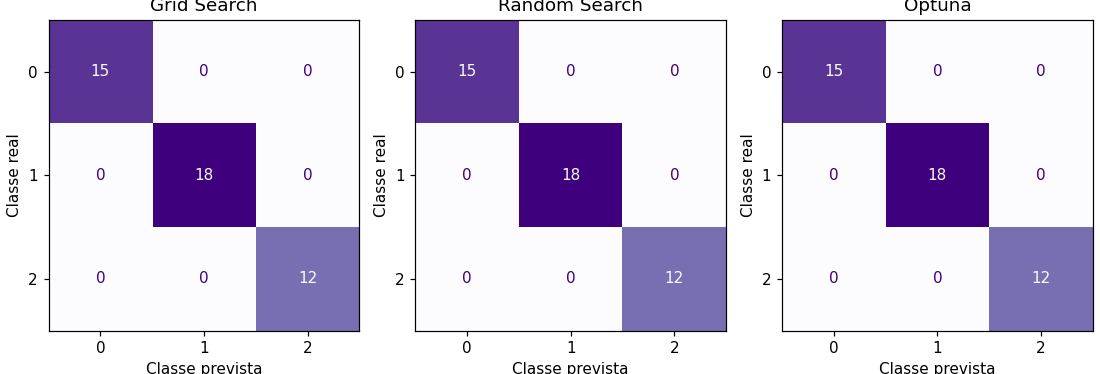

In [5]:
melhores = {nome: busca.best_params_ for nome, busca in buscas.items()}
melhores["Optuna"] = estudo.best_params
notas_cv = {nome: busca.best_score_ for nome, busca in buscas.items()}
notas_cv["Optuna"] = estudo.best_value

display(pd.DataFrame.from_dict(melhores, orient="index").round(6))

fig, eixos = plt.subplots(1, 3, figsize=(10, 3.4), layout="constrained")
resultados = []
for ax, (nome, parametros) in zip(eixos, melhores.items()):
    modelo = GradientBoostingClassifier(
        n_estimators=N_RODADAS, random_state=SEMENTE, **parametros,
    )
    modelo.fit(X_train, y_train)
    previsoes = modelo.predict(X_test)
    resultados.append({
        "Estratégia": nome,
        "Acurácia CV (%)": 100 * notas_cv[nome],
        "Acurácia teste (%)": 100 * accuracy_score(y_test, previsoes),
        "Acertos no teste": int((previsoes == y_test).sum()),
    })
    ConfusionMatrixDisplay.from_predictions(
        y_test, previsoes, labels=[0, 1, 2], ax=ax, cmap="Purples", colorbar=False,
        im_kw={"vmin": 0, "vmax": y_test.value_counts().max()},
    )
    ax.set(title=nome, xlabel="Classe prevista", ylabel="Classe real")

tabela_resultados = pd.DataFrame(resultados).set_index("Estratégia")
display(tabela_resultados.round(2))
plt.show()

## 6. Comparar o tempo e o trabalho de cada busca

A tabela soma as rodadas executadas em todos os folds. Uma tentativa completa usa 150 rodadas em cada um dos três folds, totalizando 450. Uma tentativa interrompida contribui até a última etapa em que foi avaliada. O cronômetro mede a busca, antes do treino final.

,Tentativas,Interrompidas,Rodadas somadas,Tempo (s)
Estratégia,,,,
Grid Search,12,0,5400,6.905
Random Search,12,0,5400,6.409
Optuna,12,4,4350,5.917


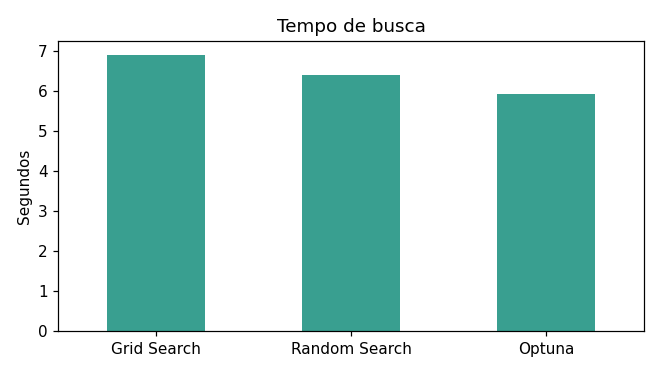

In [6]:
custos = []
for nome, busca in buscas.items():
    tentativas = len(busca.cv_results_["params"])
    custos.append([nome, tentativas, 0, tentativas * len(folds) * N_RODADAS, tempos[nome]])

interrompidas = estudo.get_trials(states=[TrialState.PRUNED])
rodadas_optuna = sum(trial.user_attrs["ultima_rodada"] * len(folds) for trial in estudo.trials)
custos.append(["Optuna", len(estudo.trials), len(interrompidas), rodadas_optuna, tempos["Optuna"]])

tabela_custos = pd.DataFrame(
    custos, columns=["Estratégia", "Tentativas", "Interrompidas", "Rodadas somadas", "Tempo (s)"],
).set_index("Estratégia")
display(tabela_custos.round(3))

ax = tabela_custos["Tempo (s)"].plot.bar(figsize=(6, 3.4), rot=0, color="#399F90")
ax.set(title="Tempo de busca", xlabel="", ylabel="Segundos")
ax.figure.tight_layout()
plt.show()

## Conclusão

As três estratégias acertaram **45 de 45 vinhos no teste**. Na validação cruzada, Random Search e Optuna empataram com **97,76%** de acurácia média. O Grid Search chegou a **97,00%**. O Grid avaliou os valores da grade e as outras duas buscas puderam experimentar taxas de aprendizado intermediárias.

**O Optuna foi a escolha mais interessante nesta execução.** Ele empatou na maior acurácia média de validação, interrompeu quatro tentativas e executou **4.350 rodadas somadas nos folds**, contra **5.400** de cada uma das outras buscas. Também teve o menor tempo medido. A escolha reflete esta divisão da base Wine e os tempos desta execução.
